# Racetrack Ring Resonator — FDTD/EME Hybrid Simulation

Built with raw meep/meow instead of BEEF's solver classes.

```
                          L_FAR (not drawn — analytic neff phase only)
                    .------------------------.
                   /                          \
              far bend                     far bend      <- standalone
                  |                              |           bend FDTD,
              L_SIDE (analytic neff)          L_SIDE          reused x2
                  |                              |
             near-left bend                near-right bend  <- THIS notebook's
                  |                              |             coupler FDTD
    "bus in" ----------------- L_C -------------------- "bus out"
                     (near straight, coupled to bus)
```

**Why this device needs raw meep, not `FDTDSolver`/`HybridSolver`:** `FDTDSolver`
only ever builds x-normal (y-z plane) sources/monitors. The two ring ports on top
of the near-left/near-right bends are y-normal (x-z) planes — nothing in BEEF
draws or measures those today, and there's no rotation helper anywhere in
`beef/geometry/_compose.py` (translation only). So this notebook hand-builds the
two FDTD simulations directly with meep, the same way
`directional_coupler_mode` hand-builds a meow cross-section without going through
`EMESolver`. See `notes.md`'s Geometry/Solver recommendations for what a
first-class `RingResonator` `DeviceGeometry` + y-normal `FDTDSolver` support would
need.

**Why this is a feedback-loop sum, not a `HybridSolver` matrix chain:** every other
`*_hybrid` example threads light through a straight cascade of sections once. A
ring is a closed loop: light re-enters the coupling region every round trip.
That's the closed-form all-pass resonator sum below, not a product of transfer
matrices.

**Simulation count — 3 FDTD runs + 13 mode solves total:**
- (a) Coupler-section FDTD, bus-excited -> t (bus->bus), k1 (bus->ring)
- (b) Coupler-section FDTD, ring-excited -> t_ring (ring->ring), k2 (ring->bus)
- (c) Standalone 90 degree bend FDTD -> b(lambda), reused for BOTH far corners
  (they're geometrically identical to each other and far enough from the bus to
  not need their own coupled-section run)
- Mode solve on the bare single-mode strip (meow direct, no BEEF solver class) at
  13 wavelengths -> neff(lambda), used for the 3 straight-propagation phases (2
  side straights + 1 far straight) AND to reference-plane-correct b(lambda)

**Wavelength strategy:** FDTD DFT monitors sample N_WL_FDTD points (moderate —
dense DFT across 5 monitors x hundreds of frequencies is expensive); the mode
solve runs at N_WL_SOLVE=13 points only (each is a real MPB solve). Both are
interpolated onto a dense N_WL_DENSE-point grid before assembling the resonance:
FDTD coefficients via magnitude + unwrapped-phase interpolation (linear real/imag
interpolation would badly distort the fast-winding propagation phase), neff via a
degree-2 polynomial fit (piecewise-linear neff would put an artificial kink in
dphi/dlambda at every solve node, corrupting resonance positions).

**Assembly (closed-form all-pass resonator, NOT a `HybridSolver` cascade):**
```
phi = 2*pi*neff(lambda)*L_outer/lambda        # L_outer = 2 side straights (short
                                                # by the ring-port reference offset)
                                                # + 1 far straight
b_corrected = b(lambda) * (per-bend reference-plane phase correction)
P = b_corrected**2 * exp(1j*phi)               # one full round trip minus the
                                                # coupler section (2 far bends + 3 straights)
E_thru = t + k1*k2*P / (1 - t_ring*P)
T = |E_thru|**2
```

**Note:** this notebook defaults to `RING_TEST_MODE=1` (reduced resolution, 2-D,
few wavelengths) — a smoke test of the whole pipeline (geometry, monitor
orientation/sign, assembly), not a physical result. Set the `RING_TEST_MODE`
environment variable to `0` before launching Jupyter for the full-res 3-D
production run (takes hours).

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.path as mpath

import meep as mp
import meow as mw

from beef import extrude_polygons
from beef.cache import CacheMissError, load_result, lookup, save_run
from beef.geometry.base import polygons_to_prisms
from beef.materials import SOI_220
from beef.results import SMatrix

Using MPI version 4.1, 1 processes


In [2]:
# Test-mode knob — TEST_MODE=True runs in minutes (2-D, low res, few
# wavelengths) to smoke-test the whole pipeline (geometry, monitor
# orientation/sign, assembly) before committing to the multi-hour full-res
# 3-D production run. Set to False (RING_TEST_MODE=0 in the environment) for
# the real result.
TEST_MODE = bool(int(os.environ.get("RING_TEST_MODE", "1")))

In [3]:
# 1. Global simulation / geometry parameters (220 nm SOI, C-band)
MATERIAL_STACK = SOI_220
WAVEGUIDE_WIDTH = 0.45     # um, single-mode strip width
GAP = 0.25                 # um, bus<->ring edge-to-edge coupling gap
R = 5.0                    # um, bend radius (centerline)
L_C = 4.0                  # um, near (coupling) straight length — the coupling-strength knob
L_SIDE = 1.0                # um, each vertical side straight (analytic neff only)
L_FAR = L_C                 # um, far straight (analytic neff only)

RESOLUTION = 20.0 if TEST_MODE else 40.0     # pts/um
THREE_D = not TEST_MODE                       # full 3-D core vs. cheap 2-D planar fallback
WL_MIN, WL_MAX = 1.50, 1.60                    # um, C-band
N_WL_FDTD = 21 if TEST_MODE else 101           # FDTD DFT points (moderate — 5 monitors x freqs is expensive)
N_WL_SOLVE = 5 if TEST_MODE else 13            # mode-solve (neff) points — each a real MPB solve
N_WL_DENSE = 501 if TEST_MODE else 2001        # dense interpolated grid, to resolve resonance dips
DPML = 0.5
SIM_HEIGHT = 1.5            # um, inner z-span when THREE_D
DECAY_TOL = 1e-11
SOURCE_MARGIN = 0.0
MONITOR_MARGIN = 0.25
S_MON = 0.5                 # um, ring-port reference plane offset above each near bend's arc end
STUB_LEN = 1.5               # um, inner (non-PML) vertical/horizontal stub length at each port
PORT_APERTURE = 3.0           # um, mode-decomposition window width at every port (generous — see
                               # intro markdown: no port sits near a neighboring waveguide at its
                               # own monitor plane, so cross-contamination isn't a concern here)

_cell_sz = (SIM_HEIGHT + 2 * DPML) if THREE_D else 0.0
_mon_sz = SIM_HEIGHT if THREE_D else 0.0
_wg_height = MATERIAL_STACK.wg_height if THREE_D else None

# Perimeter = 2 horizontal straights (L_C near + L_FAR far) + 2 vertical
# straights (2*L_SIDE) + 4 quarter bends (= one full circle, 2*pi*R).
PERIMETER = L_C + L_FAR + 2 * L_SIDE + 2 * np.pi * R
NG_GUESS = 4.3   # typical group index for a 450x220 Si strip, C-band — just for the printed FSR estimate
FSR_GUESS = (1.55 ** 2) / (NG_GUESS * PERIMETER)
print(f"Racetrack perimeter: {PERIMETER:.2f} um  ->  predicted FSR ~ {FSR_GUESS*1000:.2f} nm "
      f"(~{(WL_MAX-WL_MIN)/FSR_GUESS:.1f} resonances across {WL_MIN}-{WL_MAX} um)")
if TEST_MODE:
    print("RING_TEST_MODE=1: reduced res/2-D/few wavelengths — smoke test only, not a physical result.")

Racetrack perimeter: 41.42 um  ->  predicted FSR ~ 13.49 nm (~7.4 resonances across 1.5-1.6 um)
RING_TEST_MODE=1: reduced res/2-D/few wavelengths — smoke test only, not a physical result.


In [4]:
# Persistent on-disk simulation cache (see beef/cache/) — same shared
# examples/example_sim_cache/ directory every other example's FDTDSolver/
# EMESolver save_dir points at. This notebook hand-rolls raw meep/meow sims
# instead of going through those solver classes (see intro markdown), so it
# fingerprints+stores/loads each run itself via beef.cache's lookup()/
# save_run()/load_result() directly rather than the solver-specific
# build_run_config()/build_whole_device_config() helpers (those expect a
# DeviceGeometry + solver instance this notebook doesn't have). Assumes this
# notebook runs from its own directory (examples/ring_resonator/notebooks/),
# matching ring_resonator_hybrid.py's save_dir.
save_dir = os.path.abspath(os.path.join("..", "..", "example_sim_cache"))

# Notebook-only: never actually run a simulation here, only render from an
# already-populated cache — a script run (RING_TEST_MODE set as desired)
# populates save_dir first; this notebook is for docs/rendering and must not
# silently kick off a fresh (possibly multi-hour) meep/meow run. Raises
# CacheMissError with a clear message if something isn't cached yet.
CACHE_ONLY = True

In [5]:
# 2. Polygon helpers
def arc_polygon(cx, cy, r_inner, r_outer, theta0_deg, theta1_deg, n_pts=64):
    """Quarter-annulus wedge vertex list — same construction as
    beef/geometry/bend.py's _arc_polygon (cribbed here rather than
    importing a private function from that legacy, non-DeviceGeometry
    module)."""
    t0, t1 = np.radians(theta0_deg), np.radians(theta1_deg)
    thetas = np.linspace(t0, t1, n_pts)
    outer = [(cx + r_outer * np.cos(t), cy + r_outer * np.sin(t)) for t in thetas]
    inner = [(cx + r_inner * np.cos(t), cy + r_inner * np.sin(t)) for t in reversed(thetas)]
    return outer + inner


def rect_poly(x0, y0, x1, y1):
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]

In [6]:
# 3. Coupler-section geometry: bus straight + ring near straight + the two
#    near bends that curve the near straight's ends up into vertical stubs.
#    Bus at y=0; near straight at y_ring = WAVEGUIDE_WIDTH + GAP (center-to-
#    center pitch). Both near bends share radius R, centered directly above
#    the near straight's ends, so a wave entering a stub moving -y exits the
#    near straight moving +x (co-directional coupling with the bus).
W = WAVEGUIDE_WIDTH
Y_RING = W + GAP
STUB_X = L_C / 2 + R                    # x of both vertical stub columns
Y_BELOW = 2.0                            # inner clearance below the bus (also reused below as the
                                          # ring-port monitors' PORT_APERTURE/2 + margin clearance)
INNER_X_HALF = STUB_X + Y_BELOW          # bus extends this far past the stub columns (inner, no PML) —
                                          # sized so ring_L/ring_R's transverse PORT_APERTURE/2 window
                                          # clears the PML, same margin as Y_BELOW gives the bus monitors
Y_TOP = Y_RING + R + STUB_LEN            # inner y of the ring-port stub tops

COUPLER_SX = 2 * (INNER_X_HALF + DPML)
COUPLER_SY = (Y_TOP + DPML) - (-Y_BELOW - DPML)
COUPLER_Y_CENTER = ((Y_TOP + DPML) + (-Y_BELOW - DPML)) / 2.0


def build_coupler_polys():
    polys = [
        rect_poly(-INNER_X_HALF - DPML, -W / 2, INNER_X_HALF + DPML, W / 2),          # bus, through x-PML
        rect_poly(-L_C / 2, Y_RING - W / 2, L_C / 2, Y_RING + W / 2),                  # near straight
        arc_polygon(-L_C / 2, Y_RING + R, R - W / 2, R + W / 2, 180, 270),             # left near bend
        arc_polygon(L_C / 2, Y_RING + R, R - W / 2, R + W / 2, 270, 360),              # right near bend
        rect_poly(-STUB_X - W / 2, Y_RING + R, -STUB_X + W / 2, Y_TOP + DPML),         # left stub, through y-PML
        rect_poly(STUB_X - W / 2, Y_RING + R, STUB_X + W / 2, Y_TOP + DPML),           # right stub, through y-PML
    ]
    return polys

In [7]:
# 4. Standalone 90-degree bend geometry: x-in straight -> arc -> y-out
#    straight. Same radius R as the coupler section's near bends, so its
#    transmission b(lambda) is representative of the racetrack's other two
#    (far) corners, which are geometrically identical and isolated (far
#    enough from the bus/near straight that they don't need their own
#    coupled-section simulation).
# Built in a natural frame: input stub x in [-STUB_LEN, 0], arc center (0, R), output stub y in [R, R+STUB_LEN].
# X_MAX/Y_MIN widened past the bare bend radius by Y_BELOW (the same
# PORT_APERTURE/2 + margin clearance the coupler section uses below its bus
# straight, section 3) — without it, the arc's own outer radius (R+W/2) and
# the out_mon/norm_mon transverse mode-decomposition apertures
# (PORT_APERTURE/2 each) clip into the PML.
BEND_X_MIN, BEND_X_MAX = -STUB_LEN - DPML, R + Y_BELOW + DPML
BEND_Y_MIN, BEND_Y_MAX = -Y_BELOW - DPML, R + STUB_LEN + DPML
BEND_SX = BEND_X_MAX - BEND_X_MIN
BEND_SY = BEND_Y_MAX - BEND_Y_MIN
BEND_X_CENTER = (BEND_X_MAX + BEND_X_MIN) / 2.0
BEND_Y_CENTER = (BEND_Y_MAX + BEND_Y_MIN) / 2.0


def build_bend_polys():
    return [
        rect_poly(-STUB_LEN - DPML, -W / 2, 0.0, W / 2),               # input stub, through x-PML
        arc_polygon(0.0, R, R - W / 2, R + W / 2, -90, 0),              # the bend itself
        rect_poly(R - W / 2, R, R + W / 2, R + STUB_LEN + DPML),        # output stub, through y-PML
    ]


# Reference-plane straight lengths the bend FDTD's raw coefficient must be
# corrected by, to isolate the arc's own contribution (see run_bend_fdtd()).
BEND_D_IN = STUB_LEN - MONITOR_MARGIN
BEND_D_OUT = STUB_LEN - MONITOR_MARGIN

In [8]:
# 5. Raw-meep simulation helpers
def make_sim(polys, wl_center, cell_size, geometry_center):
    prisms = polygons_to_prisms(polys, MATERIAL_STACK.si_medium(wl_center), wg_height=_wg_height)
    return mp.Simulation(
        resolution=RESOLUTION,
        cell_size=mp.Vector3(cell_size[0], cell_size[1], _cell_sz),
        geometry_center=mp.Vector3(geometry_center[0], geometry_center[1], 0),
        boundary_layers=[mp.PML(DPML)],
        geometry=prisms,
        default_material=MATERIAL_STACK.sio2_medium(wl_center),
    )


def add_x_monitor(sim, fcen, fwidth, x, yc, width=PORT_APERTURE):
    return sim.add_mode_monitor(
        fcen, fwidth, N_WL_FDTD,
        mp.FluxRegion(center=mp.Vector3(x, yc), size=mp.Vector3(0, width, _mon_sz)),
    )


def add_y_monitor(sim, fcen, fwidth, y, xc, width=PORT_APERTURE):
    return sim.add_mode_monitor(
        fcen, fwidth, N_WL_FDTD,
        mp.FluxRegion(center=mp.Vector3(xc, y), size=mp.Vector3(width, 0, _mon_sz)),
    )


def _json_polys(polys):
    """Polygon vertex lists -> plain JSON-safe floats, for a cache config's
    geometry_polygons (mirrors beef.cache.config's own float-rounding, so
    a cache hit is exact-equality-safe against JSON round-tripping)."""
    return [[[round(float(x), 9), round(float(y), 9)] for x, y in poly] for poly in polys]


def _sim_params():
    """Every module-level constant that affects the physical result of
    run_coupler_fdtd()/run_bend_fdtd() — the raw-meep equivalent of
    FDTDSolver's vars(solver) (see beef/cache/config.py's _solver_config).
    Changing any of these must change the cache key, or a stale run could be
    served for a different simulation."""
    return {
        "waveguide_width": WAVEGUIDE_WIDTH,
        "gap": GAP,
        "R": R,
        "L_C": L_C,
        "resolution": RESOLUTION,
        "three_d": THREE_D,
        "sim_height": SIM_HEIGHT,
        "dpml": DPML,
        "decay_tol": DECAY_TOL,
        "source_margin": SOURCE_MARGIN,
        "monitor_margin": MONITOR_MARGIN,
        "port_aperture": PORT_APERTURE,
        "y_below": Y_BELOW,
        "stub_len": STUB_LEN,
        "s_mon": S_MON,
        "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
    }


def get_coeffs(sim, mon, band=1, forward=True):
    """alpha[0,:,0] = mode traveling in the monitor's implied positive
    direction (+x for an x-normal/zero-x-extent monitor, +y for a
    y-normal/zero-y-extent monitor — meep infers this from the FluxRegion's
    own zero-extent axis). alpha[0,:,1] is the opposite-traveling mode.
    forward=False is needed exactly once in this notebook: run B's source
    launches -y (down into the bend), so its own norm monitor (below the
    source, catching the leading edge of that downward pulse) must read the
    "backward" (-y) index."""
    coeff = sim.get_eigenmode_coefficients(mon, [band], eig_parity=mp.NO_PARITY)
    return coeff.alpha[0, :, 0 if forward else 1]


def get_norm_calibrated(sim, mon, forward=True):
    """Normalization amplitude for a source-adjacent monitor, magnitude
    calibrated against raw Poynting flux (mp.get_fluxes), phase taken from
    the modal coefficient.

    Empirically, meep's get_eigenmode_coefficients() undercounts the true
    launched power specifically for the "backward" (index-1) branch next to
    a y-normal EigenModeSource (needed here for run B's -y launch into the
    ring) — raw Poynting flux at the same monitor plane, cross-checked
    against a fully independent power-conservation accounting, showed the
    coefficient-based reading was too small by the same factor that
    inflated |t_ring| above 1. The forward (index-0, x-normal-source) case
    (run A, the bend run) does not show this effect, so this calibration is
    applied only where it's needed (run B's norm monitor), not everywhere."""
    coeff = get_coeffs(sim, mon, forward=forward)
    flux = np.abs(np.asarray(mp.get_fluxes(mon)))
    return np.sqrt(flux) * np.exp(1j * np.angle(coeff))

In [9]:
# 6. Coupler-section FDTD — two excitations, four ports each run.
def run_coupler_fdtd(excite, wavelengths, save_dir=None, cache_only=False):
    """excite: "bus" (run A) or "ring" (run B, source on the left stub,
    launched -y into the bend). Returns a dict of complex coefficient
    arrays [len(wavelengths)] keyed by physical quantity name.

    save_dir: persistent on-disk cache directory (see beef/cache/).
        None/"" (default) disables the cache — every call re-simulates.
    cache_only: if True, never run the simulation — a cache hit returns as
        usual, a miss raises CacheMissError instead of falling through to
        meep. Intended for notebooks that must reuse the script's
        already-populated cache rather than silently kicking off a fresh
        (possibly multi-hour) run."""
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid.run_coupler_fdtd",
            "method": excite,
            "geometry_class": "RingResonatorCoupler",
            "geometry_polygons": {"2,0": _json_polys(build_coupler_polys())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            **_sim_params(),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_coupler_fdtd({excite!r}) hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_coupler_fdtd({excite!r}): cache_only=True but no cached run "
            f"found for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = (WL_MIN + WL_MAX) / 2
    fcen = 1.0 / wl_center
    fwidth = (1.0 / WL_MIN - 1.0 / WL_MAX) * 0.5

    polys = build_coupler_polys()
    sim = make_sim(polys, wl_center, (COUPLER_SX, COUPLER_SY), (0.0, COUPLER_Y_CENTER))

    bus_l_x = -INNER_X_HALF + MONITOR_MARGIN
    bus_r_x = INNER_X_HALF - MONITOR_MARGIN
    ring_y = Y_RING + R + S_MON

    if excite == "bus":
        src_x = -INNER_X_HALF + SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
        )]
        norm_mon = add_x_monitor(sim, fcen, fwidth, bus_l_x, 0.0)
    elif excite == "ring":
        src_y = Y_TOP - SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(-STUB_X, src_y), size=mp.Vector3(PORT_APERTURE, 0, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(0, -1, 0), eig_match_freq=True,
        )]
        norm_mon = add_y_monitor(sim, fcen, fwidth, Y_TOP - MONITOR_MARGIN, -STUB_X)
    else:
        raise ValueError(f"unknown excite={excite!r}")

    bus_r_mon = add_x_monitor(sim, fcen, fwidth, bus_r_x, 0.0)
    ring_r_mon = add_y_monitor(sim, fcen, fwidth, ring_y, STUB_X)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    if excite == "bus":
        a_norm = get_coeffs(sim, norm_mon, forward=True)
        t = get_coeffs(sim, bus_r_mon, forward=True) / a_norm
        k1 = get_coeffs(sim, ring_r_mon, forward=True) / a_norm
        sim.reset_meep()
        result = {"t": t, "k1": k1}
    else:
        # launched -y — flux-calibrated normalization, see get_norm_calibrated()
        a_norm = get_norm_calibrated(sim, norm_mon, forward=False)
        t_ring = get_coeffs(sim, ring_r_mon, forward=True) / a_norm
        k2 = get_coeffs(sim, bus_r_mon, forward=True) / a_norm
        sim.reset_meep()
        result = {"t_ring": t_ring, "k2": k2}

    if save_dir:
        folder = save_run(save_dir, config, result)
        print(f"  [cache] run_coupler_fdtd({excite!r}) saved -> {folder}")
    return result

In [10]:
# 7. Standalone 90-degree bend FDTD
def run_bend_fdtd(wavelengths, save_dir=None, cache_only=False):
    """save_dir: persistent on-disk cache directory (see beef/cache/).
    None/"" (default) disables the cache — every call re-simulates.
    cache_only: if True, never run the simulation — see
    run_coupler_fdtd()'s cache_only docstring for the full semantics."""
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid.run_bend_fdtd",
            "method": "run_bend_fdtd",
            "geometry_class": "RingResonatorBend",
            "geometry_polygons": {"2,0": _json_polys(build_bend_polys())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            **_sim_params(),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_bend_fdtd hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_bend_fdtd(): cache_only=True but no cached run found for "
            f"this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = (WL_MIN + WL_MAX) / 2
    fcen = 1.0 / wl_center
    fwidth = (1.0 / WL_MIN - 1.0 / WL_MAX) * 0.5

    polys = build_bend_polys()
    sim = make_sim(polys, wl_center, (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER))

    src_x = -STUB_LEN + SOURCE_MARGIN
    sim.sources = [mp.EigenModeSource(
        mp.GaussianSource(fcen, fwidth=fwidth),
        center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
        eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
    )]
    norm_mon = add_x_monitor(sim, fcen, fwidth, -STUB_LEN + MONITOR_MARGIN, 0.0)
    out_mon = add_y_monitor(sim, fcen, fwidth, R + STUB_LEN - MONITOR_MARGIN, R)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    a_norm = get_coeffs(sim, norm_mon, forward=True)
    b_raw = get_coeffs(sim, out_mon, forward=True) / a_norm
    sim.reset_meep()

    if save_dir:
        folder = save_run(save_dir, config, b_raw)
        print(f"  [cache] run_bend_fdtd saved -> {folder}")
    return b_raw

In [11]:
# 8. Mode solve — bare single-mode strip neff(lambda), meow direct (no
#    BEEF solver class), same pattern as directional_coupler_mode.
MESH_WIDTH = 4.0
MESH_HEIGHT = 2.0


def solve_neff(wl, save_dir=None, cache_only=False):
    """save_dir: persistent on-disk cache directory (see beef/cache/).
    None/"" (default) disables the cache — every call re-solves.
    cache_only: if True, never run the solve — see run_coupler_fdtd()'s
    cache_only docstring for the full semantics."""
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid.solve_neff",
            "method": "solve_neff",
            "geometry_class": "BareStrip",
            "geometry_polygons": {
                "2,0": _json_polys([rect_poly(0.0, -W / 2, 1.0, W / 2)]),
                "1,0": _json_polys([rect_poly(0.0, -MESH_WIDTH / 2, 1.0, MESH_WIDTH / 2)]),
            },
            "waveguide_width": WAVEGUIDE_WIDTH,
            "resolution": RESOLUTION,
            "mesh_width": MESH_WIDTH,
            "mesh_height": MESH_HEIGHT,
            "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
            "wavelength": round(float(wl), 9),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"solve_neff(wl={wl!r}): cache_only=True but no cached run found "
            f"for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    length = 1.0
    wg_poly = rect_poly(0.0, -W / 2, length, W / 2)
    ox_poly = rect_poly(0.0, -MESH_WIDTH / 2, length, MESH_WIDTH / 2)
    gds_polys = {(2, 0): [wg_poly], (1, 0): [ox_poly]}

    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        x=np.linspace(-MESH_WIDTH / 2, MESH_WIDTH / 2, int(RESOLUTION * MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, int(RESOLUTION * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    cs = mw.CrossSection.from_cell(cell=cells[0], env=env)

    from meow import compute_modes_meep
    modes = compute_modes_meep(cs, num_modes=1)
    neff = float(np.real(modes[0].neff))

    if save_dir:
        save_run(save_dir, config, neff)
    return neff

In [12]:
# 9. Interpolation helpers
def interp_complex(wl_src, c, wl_dense):
    """Magnitude + unwrapped-phase interpolation — see intro markdown for
    why linear real/imag interpolation is the wrong tool here."""
    mag = np.interp(wl_dense, wl_src, np.abs(c))
    phase = np.interp(wl_dense, wl_src, np.unwrap(np.angle(c)))
    return mag * np.exp(1j * phase)


def find_dips(wl_dense, T):
    """Numpy-only local-minima + FWHM/Q/finesse extraction (no scipy, matching
    every other example in this repo)."""
    dips = []
    baseline = np.median(T)
    for i in range(1, len(T) - 1):
        if T[i] < T[i - 1] and T[i] < T[i + 1] and T[i] < 0.7 * baseline:
            half = (T[i] + baseline) / 2.0
            # walk outward to the half-depth crossings for FWHM
            lo = i
            while lo > 0 and T[lo] < half:
                lo -= 1
            hi = i
            while hi < len(T) - 1 and T[hi] < half:
                hi += 1
            if hi > lo:
                fwhm = wl_dense[hi] - wl_dense[lo]
                q = wl_dense[i] / fwhm if fwhm > 0 else np.nan
                dips.append((wl_dense[i], T[i], fwhm, q))
    return dips

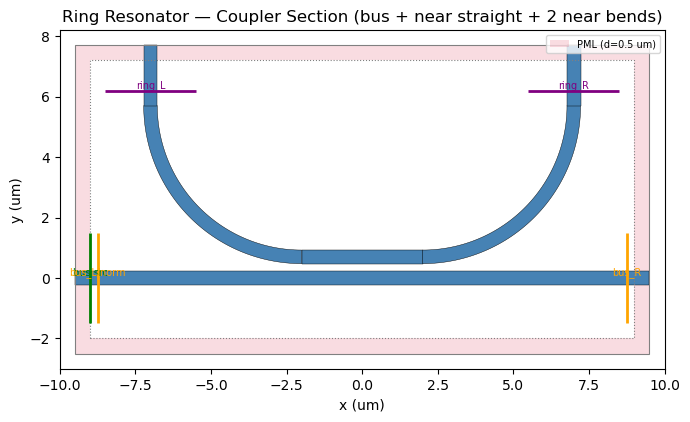

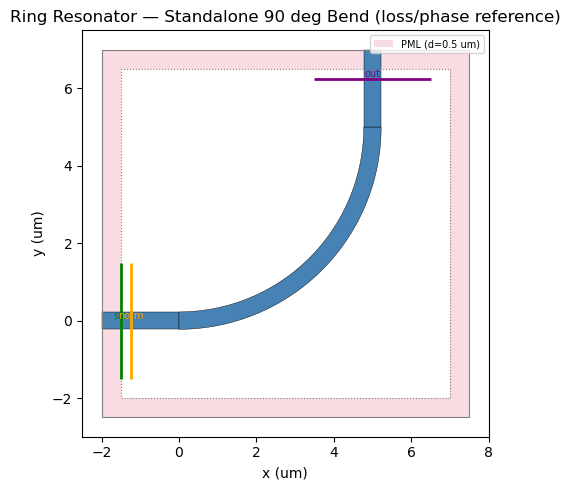

In [13]:
# 10. Geometry preview plots
def plot_cell(polys, cell_size, geometry_center, monitors, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    cx, cy = geometry_center
    sx, sy = cell_size

    outer = mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy)
    inner = mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML)
    pml_path = mpath.Path.make_compound_path(
        mpath.Path(outer.get_verts()[::-1]), mpath.Path(inner.get_verts())
    )
    ax.add_patch(mpatches.PathPatch(pml_path, facecolor="crimson", alpha=0.15, edgecolor="none",
                                     zorder=0, label="PML"))

    for poly in polys:
        ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue", edgecolor="k", lw=0.3))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy, fill=False, edgecolor="gray", lw=0.8))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML,
                                     fill=False, edgecolor="gray", linestyle=":", lw=0.8))
    for (kind, x0, y0, x1, y1, label, color) in monitors:
        ax.plot([x0, x1], [y0, y1], color=color, lw=2.0, solid_capstyle="butt")
        ax.annotate(label, (0.5 * (x0 + x1), 0.5 * (y0 + y1)), fontsize=7, color=color,
                    ha="center", va="bottom")
    ax.set_xlim(cx - sx / 2 - 0.5, cx + sx / 2 + 0.5)
    ax.set_ylim(cy - sy / 2 - 0.5, cy + sy / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x (um)")
    ax.set_ylabel("y (um)")
    ax.set_title(title)
    ax.legend(handles=[mpatches.Patch(facecolor="crimson", alpha=0.15, label=f"PML (d={DPML} um)")],
              loc="upper right", fontsize=7)
    plt.tight_layout()
    plt.show()


def _mon_seg(width, x=None, y=None, xc=None, yc=None):
    if x is not None:
        return (x, yc - width / 2, x, yc + width / 2)
    return (xc - width / 2, y, xc + width / 2, y)


plot_cell(
    build_coupler_polys(), (COUPLER_SX, COUPLER_SY), (0.0, COUPLER_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF, yc=0.0), "bus src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF + MONITOR_MARGIN, yc=0.0), "bus_L/norm", "orange"),
        ("mon", *_mon_seg(PORT_APERTURE, x=INNER_X_HALF - MONITOR_MARGIN, yc=0.0), "bus_R", "orange"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=-STUB_X, y=Y_RING + R + S_MON), "ring_L", "purple"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=STUB_X, y=Y_RING + R + S_MON), "ring_R", "purple"),
    ],
    "Ring Resonator — Coupler Section (bus + near straight + 2 near bends)",
)
plot_cell(
    build_bend_polys(), (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + SOURCE_MARGIN, yc=0.0), "src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + MONITOR_MARGIN, yc=0.0), "norm", "orange"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=R, y=R + STUB_LEN - MONITOR_MARGIN), "out", "purple"),
    ],
    "Ring Resonator — Standalone 90 deg Bend (loss/phase reference)",
)

In [14]:
# 11. Run the 3 FDTD simulations
wl_fdtd = np.linspace(WL_MIN, WL_MAX, N_WL_FDTD)

print("[1/3] Coupler-section FDTD, bus-excited...")
res_a = run_coupler_fdtd("bus", wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)
t, k1 = res_a["t"], res_a["k1"]

print("[2/3] Coupler-section FDTD, ring-excited...")
res_b = run_coupler_fdtd("ring", wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)
t_ring, k2 = res_b["t_ring"], res_b["k2"]

print("[3/3] Standalone bend FDTD...")
b_raw = run_bend_fdtd(wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)

mid = N_WL_FDTD // 2
conserve_a = np.abs(t[mid]) ** 2 + np.abs(k1[mid]) ** 2
conserve_b = np.abs(t_ring[mid]) ** 2 + np.abs(k2[mid]) ** 2
print(f"\nPower-conservation check @ mid-lambda (should be <~1, both runs are lossy/leaky by design "
      f"since each only captures 2 of several outgoing ports):")
print(f"  run A (bus-excited): |t|^2+|k1|^2 = {conserve_a:.4f}")
print(f"  run B (ring-excited): |t_ring|^2+|k2|^2 = {conserve_b:.4f}")
print(f"  reciprocity check: |k1|={np.abs(k1[mid]):.4f} vs |k2|={np.abs(k2[mid]):.4f} (should be close)")

[1/3] Coupler-section FDTD, bus-excited...
  [cache] run_coupler_fdtd('bus') hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/ef89fae7fa821367
[2/3] Coupler-section FDTD, ring-excited...
  [cache] run_coupler_fdtd('ring') hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/a3bc122cc34ccd1e
[3/3] Standalone bend FDTD...
  [cache] run_bend_fdtd hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/66346b9cd997245f

Power-conservation check @ mid-lambda (should be <~1, both runs are lossy/leaky by design since each only captures 2 of several outgoing ports):
  run A (bus-excited): |t|^2+|k1|^2 = 1.0000
  run B (ring-excited): |t_ring|^2+|k2|^2 = 0.9837
  reciprocity check: |k1|=0.1477 vs |k2|=0.1482 (should be close)


Mode solve at 5 wavelengths...
  neff fit residual (max abs): 2.53e-03


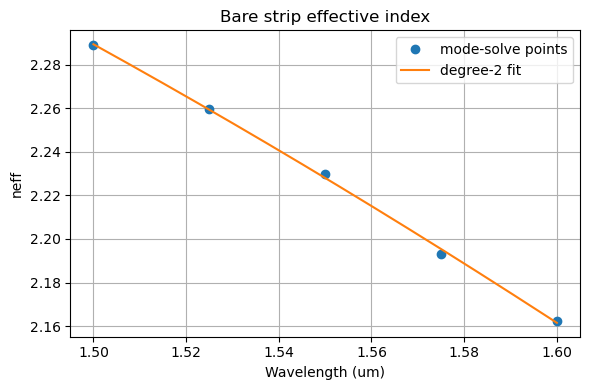

In [15]:
# 12. Mode solve — sparse neff(lambda), degree-2 polynomial fit
print(f"Mode solve at {N_WL_SOLVE} wavelengths...")
wl_solve = np.linspace(WL_MIN, WL_MAX, N_WL_SOLVE)
neff_solve = np.array([solve_neff(wl, save_dir=save_dir, cache_only=CACHE_ONLY) for wl in wl_solve])
neff_fit = np.polyfit(wl_solve, neff_solve, deg=2)
neff_resid = neff_solve - np.polyval(neff_fit, wl_solve)
print(f"  neff fit residual (max abs): {np.max(np.abs(neff_resid)):.2e}")

fig, ax = plt.subplots(figsize=(6, 4))
wl_fine = np.linspace(WL_MIN, WL_MAX, 200)
ax.plot(wl_solve, neff_solve, "o", label="mode-solve points")
ax.plot(wl_fine, np.polyval(neff_fit, wl_fine), "-", label="degree-2 fit")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("neff")
ax.set_title("Bare strip effective index")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# 13. Dense-grid assembly
wl_dense = np.linspace(WL_MIN, WL_MAX, N_WL_DENSE)
neff_dense = np.polyval(neff_fit, wl_dense)

t_d = interp_complex(wl_fdtd, t, wl_dense)
k1_d = interp_complex(wl_fdtd, k1, wl_dense)
k2_d = interp_complex(wl_fdtd, k2, wl_dense)
t_ring_d = interp_complex(wl_fdtd, t_ring, wl_dense)
b_d = interp_complex(wl_fdtd, b_raw, wl_dense)

# Reference-plane correction: the bend FDTD's raw coefficient is measured
# between its norm/output monitor planes, not the true arc endpoints —
# strip out the straight-waveguide propagation phase over BEND_D_IN +
# BEND_D_OUT so b_corrected represents the arc alone.
phi_bend_correction = 2 * np.pi * neff_dense * (BEND_D_IN + BEND_D_OUT) / wl_dense
b_corrected = b_d * np.exp(-1j * phi_bend_correction)

L_outer = 2 * (L_SIDE - S_MON) + L_FAR
phi = 2 * np.pi * neff_dense * L_outer / wl_dense
P = (b_corrected ** 2) * np.exp(1j * phi)

E_thru = t_d + k1_d * k2_d * P / (1.0 - t_ring_d * P)
T = np.abs(E_thru) ** 2

dips = find_dips(wl_dense, T)
if len(dips) >= 2:
    fsr_meas = np.mean(np.diff([d[0] for d in dips]))
else:
    fsr_meas = np.nan
print(f"Dense-grid assembly ({N_WL_DENSE} points): {len(dips)} resonance dip(s) found.")
print(f"  Measured mean FSR: {fsr_meas*1000:.3f} nm (predicted: {FSR_GUESS*1000:.2f} nm)")
if dips:
    print(f"  {'lambda (um)':>12}  {'T_min':>8}  {'FWHM (nm)':>10}  {'Q':>10}")
    for wl0, Tmin, fwhm, q in dips[:10]:
        print(f"  {wl0:12.4f}  {Tmin:8.4f}  {fwhm*1000:10.4f}  {q:10.1f}")

wl_c = wl_dense[len(wl_dense) // 2]
idx = np.argmin(np.abs(wl_dense - wl_c))
print(f"\nResults at lambda = {wl_c:.4f} um:")
print(f"  |t|={np.abs(t_d[idx]):.4f}  |k1|={np.abs(k1_d[idx]):.4f}  |k2|={np.abs(k2_d[idx]):.4f}  "
      f"|t_ring|={np.abs(t_ring_d[idx]):.4f}  |b|={np.abs(b_corrected[idx]):.4f}")
print(f"  T_through = {T[idx]:.4f}  IL = {10*np.log10(max(T[idx],1e-20)):.2f} dB")

smat = SMatrix(wavelengths=wl_dense)
smat.set(E_thru, port="through")
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength

Dense-grid assembly (501 points): 3 resonance dip(s) found.
  Measured mean FSR: 30.100 nm (predicted: 13.49 nm)
   lambda (um)     T_min   FWHM (nm)           Q
        1.5102    0.1956      0.6000      2517.0
        1.5404    0.1831      0.6000      2567.3
        1.5704    0.2173      0.6000      2617.3

Results at lambda = 1.5500 um:
  |t|=0.9890  |k1|=0.1477  |k2|=0.1482  |t_ring|=0.9807  |b|=0.9945
  T_through = 1.0000  IL = 0.00 dB


True

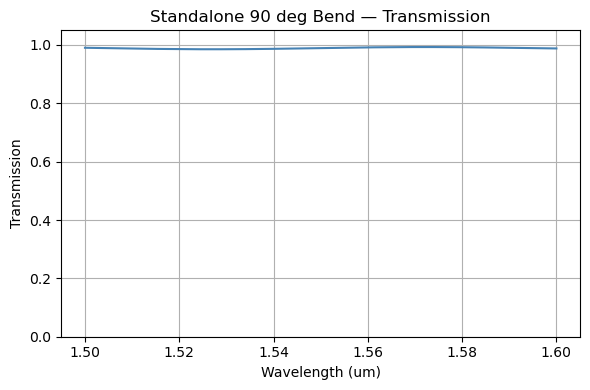

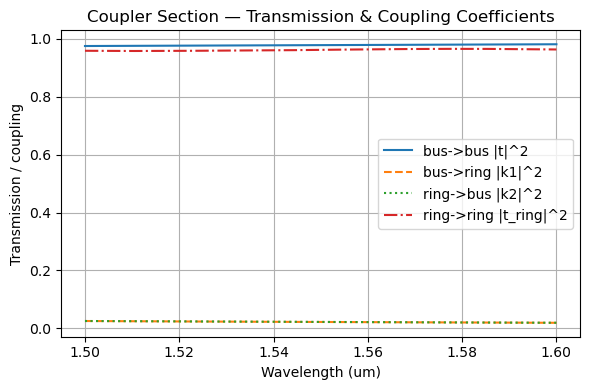

In [17]:
# 14. Independent bend / coupler-region transmission plots
T_bend = np.abs(b_d) ** 2  # note: the reference-plane phase correction (-> b_corrected)
                            # only rotates the phase, so it doesn't change |b|^2 — this
                            # magnitude curve is the same whether read off b_d or b_corrected

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, T_bend, color="steelblue")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Standalone 90 deg Bend — Transmission")
ax.grid(True)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, np.abs(t_d) ** 2, label="bus->bus |t|^2")
ax.plot(wl_dense, np.abs(k1_d) ** 2, linestyle="--", label="bus->ring |k1|^2")
ax.plot(wl_dense, np.abs(k2_d) ** 2, linestyle=":", label="ring->bus |k2|^2")
ax.plot(wl_dense, np.abs(t_ring_d) ** 2, linestyle="-.", label="ring->ring |t_ring|^2")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission / coupling")
ax.set_title("Coupler Section — Transmission & Coupling Coefficients")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

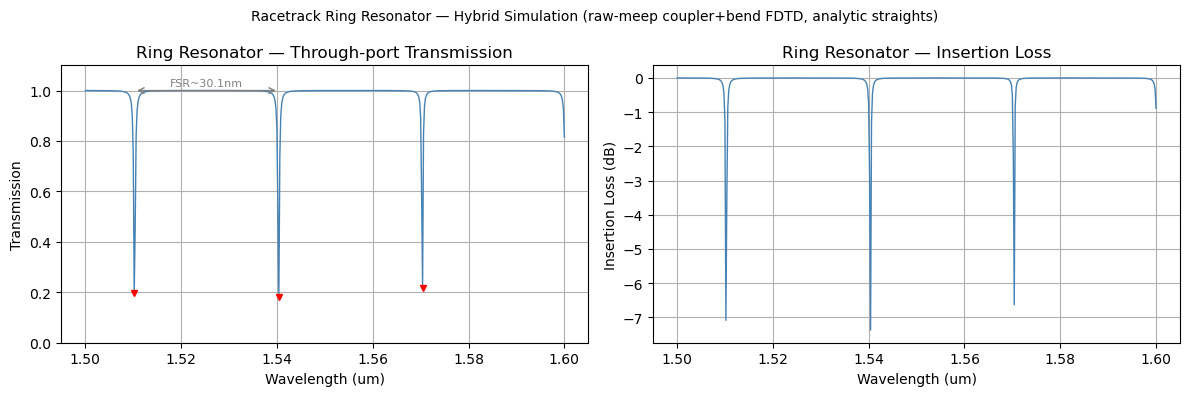

In [18]:
# 15. Results plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wl_dense, T, color="steelblue", lw=1.0)
for wl0, Tmin, fwhm, q in dips:
    ax.plot(wl0, Tmin, "rv", ms=4)
if len(dips) >= 2:
    ax.annotate("", xy=(dips[1][0], 1.0), xytext=(dips[0][0], 1.0),
                arrowprops=dict(arrowstyle="<->", color="gray"))
    ax.text(0.5 * (dips[0][0] + dips[1][0]), 1.02, f"FSR~{fsr_meas*1000:.1f}nm",
            ha="center", fontsize=8, color="gray")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Ring Resonator — Through-port Transmission")
ax.grid(True)
ax.set_ylim(0, 1.1)

ax = axes[1]
IL = 10 * np.log10(np.clip(T, 1e-20, None))
ax.plot(wl_dense, IL, color="steelblue", lw=1.0)
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title("Ring Resonator — Insertion Loss")
ax.grid(True)

plt.suptitle("Racetrack Ring Resonator — Hybrid Simulation (raw-meep coupler+bend FDTD, analytic straights)",
             fontsize=10)
plt.tight_layout()
plt.show()